# Eight seconds, or eight sightings?

`07` varied **how many** observations the model gets. This varies **where they come from**, holding the number fixed at the N the model was trained with.

That is the premise the thesis rests on. Aggregation is supposed to work because several *independent* looks at a person carry more than one look does - not because more pixels are better. If eight consecutive seconds of one clip scored the same as eight frames from eight different videos, the method would be averaging noise rather than combining evidence.

Frames were extracted at one per second, so three ways of choosing eight of them describe three different attackers:

| | what it is | what the attacker had |
| --- | --- | --- |
| `one clip` | eight consecutive seconds of a single clip | eight seconds of continuous footage |
| `one video` | eight frames spread over the clips of one video | several moments from one recording |
| `across videos` | eight frames from eight different videos | eight separate sightings, on eight different days |

The last is what the model was trained on. The first is closest to what the sweep's `video` scope will actually hand it.

In [1]:
import copy
import random

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from torch import Tensor

from aggface.data import CURRICULUM, Items
from aggface.model import checkpoint_path
from aggface.tensors import to_image
from aggface.training import identification, load_model, reconstruct
from meles.paths import repository_root
from meles.recognition import ARCFACE, FrameEmbedder

sns.set_theme(style="whitegrid")

ROOT = repository_root()
DATA = ROOT / "data"

RUN = "voxceleb2"
SEEDS = (0, 1, 2, 3, 4)
FRAMES = 8  # held fixed: this notebook varies where the observations come from, not how many
DRAW_SEED = 0
STRATEGIES = ("one clip", "one video", "across videos")

structure = pd.read_parquet(DATA / "voxceleb2.parquet", columns=["identity", "video", "clip", "second", "path"])
targets = pd.read_parquet(DATA / "voxceleb2_targets.parquet")
areas = pd.read_parquet(DATA / "voxceleb2_areas.parquet")
split = pd.read_parquet(DATA / "voxceleb2_split.parquet")
validation = list(split.loc[split["split"] == "validation", "identity"])

arcface = FrameEmbedder(ARCFACE)


def embed(batch: Tensor) -> np.ndarray:
    """L2-normalised ArcFace embeddings of aligned crops, with no detection step."""
    vectors = arcface.embed_crops([to_image(frame) for frame in batch])
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


class Chosen(Items):
    """Items whose observations are fixed in advance rather than drawn each time."""

    picks: dict[str, list[int]]

    def draw(self, identity: str, source: random.Random) -> list[int]:
        return self.picks[identity]


# Built once; each strategy is a shallow copy of it with its own picks, so every condition reads
# the same frames through the same row indexing.
base = Chosen(
    structure=structure,
    targets=targets,
    areas=areas,
    root=DATA,
    identities=validation,
    stage=len(CURRICULUM) - 1,
    frames=FRAMES,
    deterministic=True,
    all_methods=True,
    flip=False,
)
print(f"{len(base.identities)} validation identities, {len(base)} items of {FRAMES} observations")


300 validation identities, 1200 items of 8 observations


## Choosing the observations

`Items` already decides which frames an identity may be observed through - it leaves out the video the target came from, so no strategy can rebuild the target from its own recording. What changes here is only which of the remaining frames are picked, so the three conditions differ in observation diversity and in nothing else.

An identity short of frames for a strategy falls back to its largest clip or video and repeats, which is the same thing the normal draw does.

In [2]:
def round_robin(groups: list[list[int]]) -> list[int]:
    """One from each group in turn, so a selection spreads over the groups before repeating one."""
    taken = []
    for position in range(max(len(group) for group in groups)):
        taken.extend(group[position] for group in groups if position < len(group))
    return taken


def eligible(identity: str) -> pd.DataFrame:
    """The frames an identity may be observed through, with the row each one has in `base`."""
    rows = np.concatenate(base.videos[identity])
    frame = frames_by_path.loc[[base.paths[row] for row in rows]].copy()
    frame["row"] = rows
    return frame


def choose(frame: pd.DataFrame, strategy: str, source: random.Random) -> list[int]:
    """The rows of the FRAMES observations one item is built from."""
    if strategy == "one clip":
        sizes = frame.groupby(["video", "clip"]).size()
        usable = sizes[sizes >= FRAMES]
        video, clip = source.choice(sorted(usable.index)) if len(usable) else sizes.idxmax()
        shot = frame[(frame["video"] == video) & (frame["clip"] == clip)]
        chosen = list(shot.sort_values("second")["row"])
    elif strategy == "one video":
        sizes = frame.groupby("video").size()
        usable = sizes[sizes >= FRAMES]
        video = source.choice(sorted(usable.index)) if len(usable) else sizes.idxmax()
        shots = frame[frame["video"] == video].sort_values("second").groupby("clip")
        chosen = round_robin([list(shot["row"]) for _, shot in shots])
    else:
        shots = [list(shot["row"]) for _, shot in frame.groupby("video")]
        source.shuffle(shots)
        chosen = round_robin(shots)
    # Repeat rather than shrink: the model takes a fixed N, and a repeated observation is a
    # truthful item - the attacker simply saw less.
    return (chosen * FRAMES)[:FRAMES]


frames_by_path = structure.set_index("path")
pools = {identity: eligible(identity) for identity in base.identities}

sets = {}
for strategy in STRATEGIES:
    source = random.Random(DRAW_SEED)
    items = copy.copy(base)
    items.picks = {identity: choose(pool, strategy, source) for identity, pool in pools.items()}
    sets[strategy] = items

spread = []
for strategy, items in sets.items():
    for identity, chosen in items.picks.items():
        picked = frames_by_path.loc[[items.paths[row] for row in chosen]]
        spread.append(
            {
                "strategy": strategy,
                "videos": picked["video"].nunique(),
                "clips": picked.groupby(["video", "clip"]).ngroups,
                "distinct frames": len(set(chosen)),
            }
        )
pd.DataFrame(spread).groupby("strategy").mean().loc[list(STRATEGIES)].round(2)


,videos,clips,distinct frames
strategy,,,
one clip,1.00,1.00,8.0
one video,1.00,3.31,8.0
across videos,7.89,7.89,8.0


## What each attacker recovers

Every seed is scored on all three strategies, so the spread across seeds says whether a difference between them is larger than the difference between two runs of the same thing.

In [3]:
records = []
for seed in SEEDS:
    checkpoint = checkpoint_path(RUN, seed)
    model, _ = load_model(checkpoint)
    for strategy, items in sets.items():
        scores = identification(model, items, embed, ranks=(1,))
        for key, value in scores.items():
            method = key.removeprefix("rank1").lstrip("_") or "overall"
            records.append({"seed": seed, "strategy": strategy, "method": method, "rank1": value})
        print(f"seed {seed}  {strategy:14s} overall {scores['rank1']:.3f}", flush=True)

diversity = pd.DataFrame(records)
summary = diversity.pivot_table(index="method", columns="strategy", values="rank1", aggfunc=["mean", "std"])
summary.round(3)

seed 0  one clip       overall 0.580
seed 0  one video      overall 0.602
seed 0  across videos  overall 0.713
seed 1  one clip       overall 0.581
seed 1  one video      overall 0.596
seed 1  across videos  overall 0.708
seed 2  one clip       overall 0.587
seed 2  one video      overall 0.611
seed 2  across videos  overall 0.704
seed 3  one clip       overall 0.578
seed 3  one video      overall 0.608
seed 3  across videos  overall 0.716
seed 4  one clip       overall 0.592
seed 4  one video      overall 0.608
seed 4  across videos  overall 0.712


mean                              std                   
strategy     across videos one clip one video across videos one clip one video
method                                                                        
blackbar             0.113    0.059     0.056         0.011    0.007     0.019
gaussianblur         0.985    0.859     0.896         0.006    0.021     0.009
none                 0.991    0.931     0.951         0.005    0.004     0.010
overall              0.710    0.584     0.605         0.004    0.006     0.006
pixelation           0.753    0.485     0.517         0.016    0.014     0.020

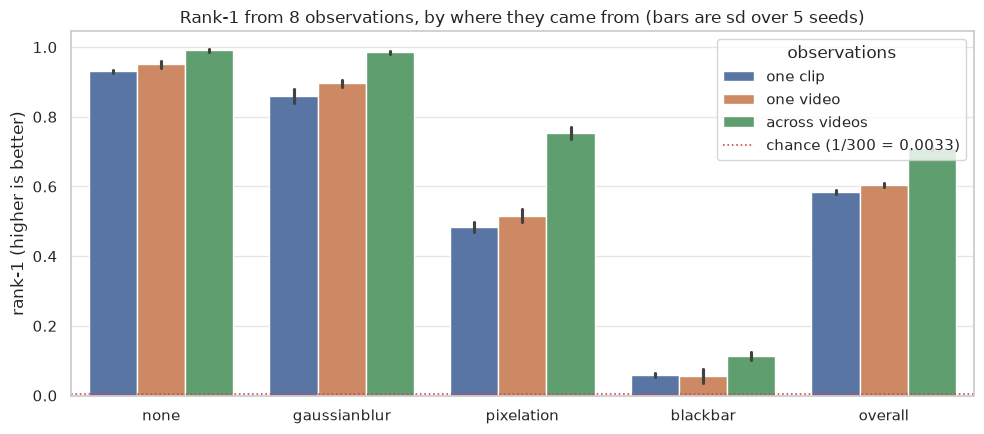

In [4]:
order = [*CURRICULUM, "overall"]
people = len(base) // len(CURRICULUM)

fig, axis = plt.subplots(figsize=(10, 4.5))
sns.barplot(
    diversity, x="method", y="rank1", hue="strategy",
    order=order, hue_order=list(STRATEGIES), errorbar="sd", ax=axis,
)
axis.axhline(1 / people, color="#C44E52", linestyle=":", linewidth=1.2,
             label=f"chance (1/{people} = {1 / people:.4f})")
axis.set_title(f"Rank-1 from {FRAMES} observations, by where they came from (bars are sd over {len(SEEDS)} seeds)")
axis.set_ylabel("rank-1 (higher is better)")
axis.set_xlabel("")
axis.legend(title="observations")
fig.tight_layout()
plt.show()

One identity under each strategy: the observations the model was given, and what it produced from them. The anonymization is the same in every row, and so is the number of frames - only their provenance differs.

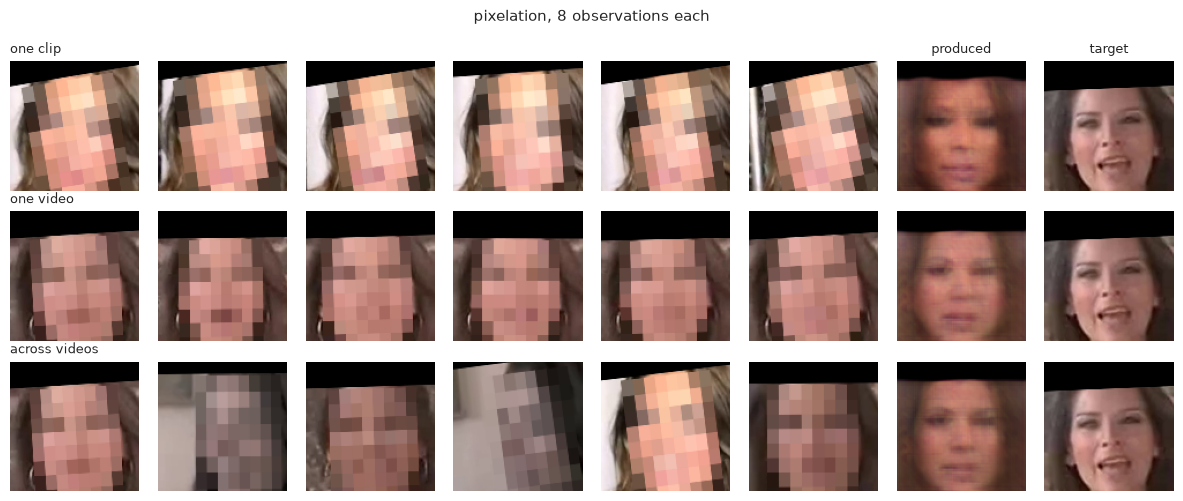

In [5]:
SHOWN = min(6, FRAMES)
PERSON = 3
METHOD = CURRICULUM.index("pixelation")

model, _ = load_model(checkpoint_path(RUN, SEEDS[0]))

fig, axes = plt.subplots(len(STRATEGIES), SHOWN + 2, figsize=(1.5 * (SHOWN + 2), 1.7 * len(STRATEGIES)))
for row, strategy in enumerate(STRATEGIES):
    anonymized, clear, _ = sets[strategy][PERSON * len(CURRICULUM) + METHOD]
    produced = reconstruct(model, anonymized, METHOD)[0]

    for column in range(SHOWN):
        axes[row, column].imshow(to_image(anonymized[column])[:, :, ::-1])
    axes[row, SHOWN].imshow(to_image(produced)[:, :, ::-1])
    axes[row, SHOWN + 1].imshow(to_image(clear)[:, :, ::-1])
    for axis in axes[row]:
        axis.set_axis_off()
    axes[row, 0].set_title(strategy, loc="left", fontsize=9)

axes[0, SHOWN].set_title("produced", fontsize=9)
axes[0, SHOWN + 1].set_title("target", fontsize=9)
fig.suptitle(f"{CURRICULUM[METHOD]}, {FRAMES} observations each", fontsize=11)
fig.tight_layout()
plt.show()

What to read off it:

- **A gap between `one clip` and `across videos`** is the premise of the whole experiment holding: the same number of frames is worth more when they are independent looks at the person.
- **The size of that gap per anonymization** says where diversity matters. The harder the method, the less any single frame carries, so the more the model should depend on having several genuinely different ones.
- **`one video` sitting between them** is the number that matters for the sweep, because a `video` scope group is exactly that: several clips of one recording.
- **A gap smaller than the seed spread** would mean the opposite - that the aggregation is pooling pixels rather than combining evidence, and that the corpus's video count is not the binding constraint it appears to be.